# Learned Representations and Transfer Learning - Concepts

**Business problem:** sort clothing images into five catalog categories when target training labels are limited.
Should the shop train directly on pixels or reuse an existing visual representation?

In this notebook, we will:
1. Distinguish a learned representation, a prediction head and an autoencoder.
2. Explain which parameters and model state stay fixed in frozen-feature transfer.
3. Design a label-budget-aware baseline comparison with separate validation and test evidence.
4. Connect category errors and domain mismatch to a qualified business recommendation.

**SW07 Lecture 4 companion. Prerequisites:** CNNs from Lecture 3, classification and validation.
The lecture's unsupervised-learning narrative also includes representations and autoencoders.
This practical illustrates **supervised transfer learning**, not unsupervised training: ImageNet pretraining and the new head use labels.
It does not replace the lecture's autoencoder explanation and has no decoder or reconstruction objective.

One prepared comparison fits the 10-minute demonstration slot. The complete [exercise](transfer_learning_exercise.ipynb)
is a separate practical; consult the [solution](transfer_learning_solution.ipynb) after your own interpretation.

## 1. Representation, reconstruction and classification

`image -> encoder -> feature vector` is a representation pipeline.
An autoencoder adds `feature vector -> decoder -> reconstructed image` and learns from a reconstruction objective.
Our pipeline instead adds `feature vector -> trained classifier -> five category scores`.
A smaller vector is not automatically an unsupervised representation or proof that useful business information is preserved.

The practical compares `784 raw pixels -> linear head` with `frozen ResNet-18 -> 512 features -> linear head`.
The pretrained network supplies supervised ImageNet knowledge; target labels fit the new head.

## 2. Inspect the actual image domain

Fashion-MNIST images are 28 x 28, grayscale and centered. They are not representative catalog photos.
The five categories are trousers, sandals, sneakers, bags and ankle boots.
The grid contains the first available official training example per category, not test examples or cherry-picked successes.
Images must already be present under the repository's `00_Data/FashionMNIST/raw/` folder.

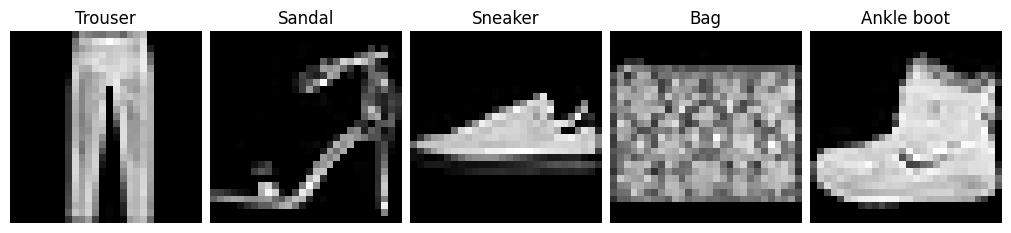

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from fashion_mnist_data import load_fashion_partition

DATA_ROOT = Path('../../../00_Data').resolve()
TARGET_CLASS_IDS = (1, 5, 7, 8, 9)
CLASS_NAMES = ['Trouser', 'Sandal', 'Sneaker', 'Bag', 'Ankle boot']
images, labels = load_fashion_partition(DATA_ROOT, training=True)
figure, axes = plt.subplots(1, 5, figsize=(10, 3), layout='constrained')
for category, name, axis in zip(TARGET_CLASS_IDS, CLASS_NAMES, axes):
    position = int(np.flatnonzero(labels == category)[0])
    axis.imshow(images[position], cmap='gray', vmin=0, vmax=255)
    axis.set_title(name)
    axis.axis('off')
plt.show()

## 3. Freeze the feature extractor, train the head

ResNet-18 originally predicts 1,000 ImageNet classes. Transformers supplies its PyTorch encoder without that classifier, exposing 512 pooled features.
This remains a CNN, not a transformer architecture. The original head is not trained on our five target categories.
`requires_grad_(False)` prevents updates to encoder parameters. `eval()` also fixes batch-normalization state.
The new `Linear(512, 5)` head has 2,565 trainable weights and biases; the raw-pixel head has 3,925.

Heads produce unnormalized scores, called logits. PyTorch's `CrossEntropyLoss` includes the log-softmax calculation;
adding softmax before it is unnecessary and changes the intended loss calculation.
A feature coordinate has no guaranteed human-readable meaning. Neither features nor predictions establish causality.

In [2]:
from IPython.display import display
import pandas as pd

parameter_counts = pd.Series({
    'Raw pixels: 784 to 5': 784 * 5 + 5,
    'Frozen features: 512 to 5': 512 * 5 + 5,
}, name='Trainable head parameters')
display(parameter_counts.to_frame())
print('Training-majority accuracy with five balanced categories:', 1 / 5)

,Trainable head parameters
Raw pixels: 784 to 5,3925
Frozen features: 512 to 5,2565


Training-majority accuracy with five balanced categories: 0.2


## 4. Respect label budgets and evaluation boundaries

Use 5,000 balanced training and 5,000 balanced validation images from the official training partition.
Keep the other 20,000 target training images unused. Evaluate fixed choices on the 5,000 official test images in these categories.
Validation chooses each head's best epoch and the pipeline with highest validation accuracy.
The 5,000-label budget counts target training labels only: validation, balanced sampling and external ImageNet pretraining also use labels.

Always guessing one category gives 20% accuracy on these balanced five-category partitions.
A linear raw-pixel head is a stronger baseline. Compare both full pipelines under identical target labels and validation rules.
ResNet's resizing, cropping and ImageNet features differ from the raw-pixel path; this is not a clean estimate of pretraining's isolated effect.

## 5. Fixed mappings can be cached; changing mappings cannot

Repeat a grayscale image across three channels, then apply the selected weights' prescribed preprocessing.
Repetition adds no color information; resizing adds no missing detail; cropping can remove useful boundaries.
An evaluation-mode frozen encoder maps each image independently to fixed features.
Cache keys must reflect images, preprocessing, weights, package versions and device.

When fine-tuning changes encoder weights, old cached features no longer represent the current mapping and cannot carry encoder gradients.
Pretrained weights may need a first-use download even when the Fashion-MNIST images are local.
Latency, cache storage and external pretraining cost still count in the complete system.

## Summary and knowledge check

- A feature extractor is not automatically an autoencoder or an unsupervised model.
- Freezing parameters and using evaluation mode serve different purposes.
- A label-budget-aware baseline comparison needs fixed validation rules and a protected test partition.
- Benchmark accuracy is not operational catalog quality or causal business value.

1. Which weights change in the frozen ResNet pipeline? Why call `eval()` as well?
2. Does a 512-dimensional vector imply unsupervised learning or reconstruction?
3. What does the 5,000-training-label budget omit?
4. Why can cached features not be used as though they support CNN fine-tuning?

**Optional practical:** investigate fine-tuning or smaller target training-label budgets using training and validation only.
Keep these outside the 10-minute lecture activity and plan fresh evaluation before redesigning from test findings.

## References

**Required student source:** Zalando Research. *Fashion-MNIST*: dataset, class labels and data license.
https://github.com/zalandoresearch/fashion-mnist

**Official technical documentation:** [Transformers 4.40.2 PyTorch ResNet](https://huggingface.co/docs/transformers/v4.40.2/model_doc/resnet),
[the pinned Microsoft ResNet-18 checkpoint](https://huggingface.co/microsoft/resnet-18/tree/65a5785d9156231087c481e0c7dd33a5ff6f7e3e),
[PyTorch transfer-learning tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html),
[CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

**Optional instructor reference:** He, K., Zhang, X., Ren, S., & Sun, J. (2016).
*Deep Residual Learning for Image Recognition*. CVPR. https://arxiv.org/abs/1512.03385

**Required conceptual reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023).
*An Introduction to Statistical Learning: With Applications in Python*. Springer. Neural-network material.
https://www.statlearning.com/

**Environment:** [Pinned PyTorch requirements](../requirements-transfer-learning-pytorch.txt).
Transformers provides the PyTorch encoder and its image processor; torchvision and TensorFlow are not required.
The comparison uses results from the executed cells, not earlier torchvision/Keras runs or published ImageNet scores.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [3]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-arm64-i386-64bit
Python: 3.11.11
Date: 2026-10-25T22:53:49
